# Dengue in Vietnam: when and where does the season hit, and does rain warn us early?
Google Data Analytics Capstone, Track B. Phases: **Ask → Prepare → Process → Analyze → Share → Act**. The 503 MB OpenDengue spatial file is filtered with **DuckDB**; everything after that is **pandas**.

## 1. Ask
- **Client:** a pest-control services company (or a provincial Center for Disease Control) planning vector-control staff, insecticide stock and community campaigns for the dengue season.
- **Business task:** identify **when in the year and where** reported dengue cases in Vietnam rise, and **how strongly they follow rainfall and temperature in the preceding months**, so the client can prepare one to two months before each regional peak.
- **Stakeholders:** operations director, regional managers (North, Central coast, Central Highlands, South), finance, public-health partners.
- **Metrics:** cases per month; peak month and season length; incidence per 100,000 (if population is added); outbreak years (> mean + 2 SD); Spearman correlation of rainfall / temperature at lag 0–3 months with cases.

Full reasoning and the five guiding questions: `docs/topic_selection.md`.

## 2. Prepare
Sources, license, ROCCC and limitations: `docs/data_sources.md`. Raw files come from `python scripts/download_data.py`.

In [1]:
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, CLEAN = ROOT / "data" / "raw", ROOT / "data" / "clean"
CLEAN.mkdir(parents=True, exist_ok=True)
con = duckdb.connect()
pd.set_option("display.width", 120)

### 2.1 Province-level monthly cases (Vietnam)

In [2]:
prov_raw = con.execute(f'''
    SELECT adm_1_name, calendar_start_date, calendar_end_date, CAST("Year" AS INTEGER) AS year, dengue_total,
           case_definition_standardised, T_res, UUID
    FROM read_csv('{RAW / "Spatial_extract_V1_3_1.csv"}', all_varchar = true)
    WHERE upper(adm_0_name) LIKE '%VIET%' AND S_res = 'Admin1'
''').df()
prov_raw["dengue_total"] = pd.to_numeric(prov_raw["dengue_total"])
prov_raw.to_parquet(CLEAN / "vn_province_month_raw.parquet", index=False)  # 0.1 MB instead of 503 MB
print(len(prov_raw), "rows,", prov_raw.adm_1_name.nunique(), "provinces")
print(prov_raw[["T_res", "UUID", "case_definition_standardised"]].value_counts())
print("period:", prov_raw.calendar_start_date.min(), "→", prov_raw.calendar_end_date.max())

12273 rows, 64 provinces
T_res  UUID                           case_definition_standardised
Month  TYCHO-ALL-19242017-SV_DF01-00  Total                           12273
Name: count, dtype: int64
period: 1994-02-01 → 2010-12-31


In [3]:
checks = {
    "negative counts": int((prov_raw.dengue_total < 0).sum()),
    "missing counts": int(prov_raw.dengue_total.isna().sum()),
    "duplicate province-months": int(prov_raw.duplicated(["adm_1_name", "calendar_start_date"]).sum()),
    "rows not one calendar month": int((pd.to_datetime(prov_raw.calendar_start_date).dt.to_period("M")
                                         != pd.to_datetime(prov_raw.calendar_end_date).dt.to_period("M")).sum()),
}
checks

{'negative counts': 0,
 'missing counts': 0,
 'duplicate province-months': 0,
 'rows not one calendar month': 0}

In [4]:
coverage = (prov_raw.groupby("adm_1_name")
            .agg(months=("calendar_start_date", "nunique"), first=("calendar_start_date", "min"),
                 last=("calendar_start_date", "max"), cases=("dengue_total", "sum"))
            .sort_values("cases", ascending=False))
print(coverage.months.value_counts().sort_index(ascending=False))
coverage.head(12)

months
203    30
202    13
201     5
200     3
191     1
168     7
167     1
166     1
84      3
Name: count, dtype: int64


,months,first,last,cases
adm_1_name,,,,
HO CHI MINH CITY,203,1994-02-01,2010-12-01,115304
TIEN GIANG,203,1994-02-01,2010-12-01,83373
BEN TRE,201,1994-02-01,2010-12-01,82532
DONG THAP,203,1994-02-01,2010-12-01,72717
BINH THUAN,200,1994-02-01,2010-12-01,68206
CA MAU,202,1994-02-01,2010-12-01,68024
AN GIANG,203,1994-02-01,2010-12-01,67580
KIEN GIANG,203,1994-02-01,2010-12-01,66764
DONG NAI,203,1994-02-01,2010-12-01,63879


### 2.2 National series (all resolutions) and cross-check

In [5]:
nat = pd.read_csv(RAW / "National_extract_V1_3_1.csv", low_memory=False)
nat_vn = nat[nat.adm_0_name.str.upper().str.contains("VIET")].copy()
print(nat_vn.groupby("T_res").Year.agg(["min", "max", "count"]))
cross = pd.concat([
    prov_raw.groupby("year").dengue_total.sum().rename("sum_of_provinces"),
    nat_vn[nat_vn.T_res == "Month"].groupby("Year").dengue_total.sum().rename("national_monthly"),
    nat_vn[nat_vn.T_res == "Year"].set_index("Year").dengue_total.rename("national_yearly"),
], axis=1).loc[1994:2010]
cross

        min   max  count
T_res                   
Month  1995  2025    183
Week   2016  2023     93
Year   1960  2022     41


,sum_of_provinces,national_monthly,national_yearly
1994,42828.0,NaN,44944.0
1995,80447.0,80447.0,NaN
1996,89963.0,89963.0,NaN
1997,107188.0,NaN,108000.0
1998,234920.0,234920.0,NaN
1999,35868.0,35868.0,NaN
2000,25269.0,25269.0,NaN
2001,42013.0,NaN,42878.0
2002,31608.0,NaN,31760.0
2003,49751.0,49751.0,NaN


### 2.3 Weather (NASA POWER, 11 provincial capitals)

In [6]:
def read_power(path):
    lines = path.read_text().splitlines()
    start = lines.index("-END HEADER-") + 1
    from io import StringIO
    w = pd.read_csv(StringIO("\n".join(lines[start:])))
    w.insert(0, "file", path.stem)
    return w

weather_wide = pd.concat([read_power(p) for p in sorted((RAW / "weather").glob("*.csv"))], ignore_index=True)
print(weather_wide.shape, weather_wide.file.nunique(), "locations,", weather_wide.YEAR.min(), "→", weather_wide.YEAR.max())
print("missing (-999):", int((weather_wide.select_dtypes("number") == -999).sum().sum()))
weather_wide.head(3)

(1023, 16) 11 locations, 1994 → 2024
missing (-999): 0


,file,PARAMETER,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANN
0,an-giang,PRECTOTCORR,1994,0.34,0.00,0.94,2.11,5.27,8.88,5.12,7.47,6.82,4.37,0.95,1.24,3.64
1,an-giang,PRECTOTCORR,1995,0.34,0.00,0.43,1.06,6.45,7.91,9.07,8.52,9.27,9.88,3.26,2.02,4.88
2,an-giang,PRECTOTCORR,1996,0.78,0.13,0.13,3.96,8.40,6.64,9.74,7.22,8.10,10.82,6.75,1.31,5.35


### Prepare: what the checks show
- **Scope:** province-level monthly data for 64 provinces, 1994-02 → 2010-12 (one source, Project Tycho via OpenDengue), with no negative, missing or duplicate rows. This supports seasonality, regional comparison and the weather-lag analysis at province level.
- **Consistency:** the sum of provinces matches the national monthly series exactly for 1995–2009.
- **Current:** province data stops in 2010; the national monthly series for 2024–2025 is used to check whether the seasonal timing still holds.
- **Weather:** 11 provincial capitals, 1994–2024, no missing values.

## 3. Process
Every step is logged with its row count; the table at the end of this section is copied into `docs/changelog.md`.

In [7]:
import sys
sys.path.insert(0, str(ROOT / "scripts"))
from regions import REGION, ORDER

log = []
def step(name, n, note=""):
    log.append((name, n, note))
    print(f"{name:<62} {n:>8,}")

prov = prov_raw.rename(columns={"adm_1_name": "province", "dengue_total": "cases"}).copy()
step("Vietnam province-month rows (raw)", len(prov))
prov["date"] = pd.to_datetime(prov.calendar_start_date)
prov["month"] = prov.date.dt.month
prov["region"] = prov.province.map(REGION)
assert prov.region.notna().all(), "every province must have a region"
prov = prov[["province", "region", "date", "year", "month", "cases"]].sort_values(["province", "date"]).reset_index(drop=True)
step("after parsing month and adding region (no rows removed)", len(prov), "4 regions, 64 provinces")
complete = prov.groupby(["province", "year"]).month.transform("size") == 12
step("rows in complete province-years (used for yearly averages)", int(complete.sum()),
     "1994 lacks January; provinces created in 1997/2004 start mid-period")

Vietnam province-month rows (raw)                                12,273
after parsing month and adding region (no rows removed)          12,273
rows in complete province-years (used for yearly averages)       11,640


In [8]:
MONTHS = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"]
w = weather_wide.melt(id_vars=["file", "PARAMETER", "YEAR"], value_vars=MONTHS, var_name="mon", value_name="value")
w["month"] = w.mon.map({m: i + 1 for i, m in enumerate(MONTHS)})
weather = (w.pivot_table(index=["file", "YEAR", "month"], columns="PARAMETER", values="value").reset_index()
             .rename(columns={"file": "slug", "YEAR": "year", "T2M": "temp_c", "RH2M": "rh_pct"}))
days = pd.to_datetime(dict(year=weather.year, month=weather.month, day=1)).dt.days_in_month
weather["rain_mm"] = (weather.PRECTOTCORR * days).round(1)          # mm/day → mm/month
weather = weather.drop(columns="PRECTOTCORR").sort_values(["slug", "year", "month"]).reset_index(drop=True)
for k in (1, 2, 3):                                                   # lags on the full weather series
    for v in ("rain_mm", "temp_c", "rh_pct"):
        weather[f"{v}_lag{k}"] = weather.groupby("slug")[v].shift(k)
step("weather location-months, long format (11 locations × 31 years)", len(weather), "rain converted to mm/month")

prov["slug"] = prov.province.str.lower().str.replace(" - ", "-").str.replace(" ", "-")
pw = prov.merge(weather, on=["slug", "year", "month"], how="inner")
step("province-months joined to weather (11 provinces)", len(pw), "inner join on province + year + month")
print(pw.groupby("province").size().to_string())

weather location-months, long format (11 locations × 31 years)    4,092
province-months joined to weather (11 provinces)                  2,191
province
AN GIANG            203
BINH THUAN          200
CA MAU              202
DA NANG CITY        168
DAK LAK             202
HA NOI CITY         203
HAI PHONG CITY      203
HO CHI MINH CITY    203
KHANH HOA           201
QUANG TRI           203
TIEN GIANG          203


In [9]:
yr = nat_vn[nat_vn.T_res == "Year"].set_index("Year").dengue_total
mo = nat_vn[nat_vn.T_res == "Month"].groupby("Year").dengue_total.agg(["size", "sum"])
wk = nat_vn[nat_vn.T_res == "Week"].groupby("Year").dengue_total.agg(["size", "sum"])
mo_full, wk_full = mo.loc[mo["size"] == 12, "sum"], wk.loc[wk["size"] >= 52, "sum"]
national = pd.concat([
    yr.rename("cases").to_frame().assign(source="annual figure"),
    mo_full[~mo_full.index.isin(yr.index)].rename("cases").to_frame().assign(source="sum of 12 months"),
    wk_full[~wk_full.index.isin(yr.index) & ~wk_full.index.isin(mo_full.index)].rename("cases").to_frame()
        .assign(source="sum of 52 weeks"),
]).sort_index()
national.index.name = "year"
step("national annual series: years with a complete total", len(national),
     "one source per year, no double counting; 2023 (41 weeks) and 2025 (3 months) left out")
print("years without a complete total:", sorted(set(range(1960, 2025)) - set(national.index)))
print(national.source.value_counts().to_string())

national annual series: years with a complete total                  57
years without a complete total: [1961, 1967, 1968, 1969, 1970, 1971, 1975, 2023]
source
annual figure       41
sum of 12 months    15
sum of 52 weeks      1


In [10]:
import re, unicodedata, json

def key(name):
    """Match province names across OpenDengue, the statistics office and geoBoundaries."""
    s = str(name).replace("Ð", "D").replace("Đ", "D").replace("đ", "d")
    s = "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn").upper()
    s = re.sub("CITY$", "", re.sub("^TP", "", re.sub("[^A-Z]", "", s)))
    return {"HUE": "THUATHIENHUE", "HATAY": "HANOI", "CONDAO": "BARIAVUNGTAU"}.get(s, s)

pop = pd.read_csv(RAW / "population" / "nso_V02.03-07_population_1995_2010.csv")
pop["k"] = pop.area.map(key)
pop = pop[pop.k.isin(set(prov.province.map(key)))]          # drop national and regional totals
step("population: province-years 1995–2010 (statistics office, V02.03-07)", len(pop), "average population, thousand people")
cases_y = (prov[prov.year.between(2004, 2010)].assign(k=prov.province.map(key))
             .groupby(["k", "year"]).cases.sum().reset_index())   # Ha Tay is added to Ha Noi in every year
pop_y = pop[pop.year.between(2004, 2010)].groupby(["k", "year"]).population_thousand.sum().reset_index()
inc_y = cases_y.merge(pop_y, on=["k", "year"], how="inner", validate="1:1")
assert len(inc_y) == len(cases_y) == 63 * 7, "every province-year needs a population"
inc_y["incidence"] = inc_y.cases / (inc_y.population_thousand * 1000) * 1e5
inc_y.to_csv(CLEAN / "province_year_incidence.csv", index=False)
step("province-years with cases and population, 2004–2010", len(inc_y),
     "63 provinces × 7 years on the same boundaries; Ha Tay merged into Ha Noi")

population: province-years 1995–2010 (statistics office, V02.03-07)    1,024


province-years with cases and population, 2004–2010                 441


In [11]:
prov.drop(columns="slug").to_parquet(CLEAN / "province_month.parquet", index=False)
pw.to_csv(CLEAN / "province_month_weather.csv", index=False)
national.to_csv(CLEAN / "national_annual.csv")
changelog = pd.DataFrame(log, columns=["step", "rows", "note"])
print("| Step | Rows | Note |")
print("| --- | ---: | --- |")
for r in changelog.itertuples():
    print(f"| {r.step} | {r.rows:,} | {r.note} |")

| Step | Rows | Note |
| --- | ---: | --- |
| Vietnam province-month rows (raw) | 12,273 |  |
| after parsing month and adding region (no rows removed) | 12,273 | 4 regions, 64 provinces |
| rows in complete province-years (used for yearly averages) | 11,640 | 1994 lacks January; provinces created in 1997/2004 start mid-period |
| weather location-months, long format (11 locations × 31 years) | 4,092 | rain converted to mm/month |
| province-months joined to weather (11 provinces) | 2,191 | inner join on province + year + month |
| national annual series: years with a complete total | 57 | one source per year, no double counting; 2023 (41 weeks) and 2025 (3 months) left out |
| population: province-years 1995–2010 (statistics office, V02.03-07) | 1,024 | average population, thousand people |
| province-years with cases and population, 2004–2010 | 441 | 63 provinces × 7 years on the same boundaries; Ha Tay merged into Ha Noi |


## 4. Analyze

### 4.1 Long-term trend and outbreak years (national)

In [12]:
recent = national.loc[1980:, "cases"]            # surveillance before 1980 is too patchy for a baseline
threshold = recent.mean() + 2 * recent.std()
outbreaks = recent[recent > threshold]
typical = recent.median()
baseline = {f"{a}–{b}": national.loc[a:b, "cases"].median() for a, b in [(1980, 1999), (2000, 2009), (2010, 2024)]}
print(f"1980–2024: mean {recent.mean():,.0f}, SD {recent.std():,.0f}, outbreak threshold (mean + 2 SD) {threshold:,.0f}")
print("outbreak years:", {y: f"{c:,.0f} ({c / typical:.1f}× the median year)" for y, c in outbreaks.items()})
print("median year by period:", {k: f"{v:,.0f}" for k, v in baseline.items()})
print("largest years:", recent.nlargest(6).astype(int).to_dict())

1980–2024: mean 96,419, SD 81,119, outbreak threshold (mean + 2 SD) 258,657
outbreak years: {1987: '354,517 (4.8× the median year)', 2019: '320,702 (4.3× the median year)', 2022: '367,729 (5.0× the median year)'}
median year by period: {'1980–1999': '51,004', '2000–2009': '62,936', '2010–2024': '109,041'}
largest years: {2022: 367729, 1987: 354517, 2019: 320702, 1998: 234920, 2017: 172232, 1983: 143380}


### 4.2 Seasonality (all provinces, complete years 1995–2010)

In [13]:
core = prov[prov.year.between(1995, 2010)]
nat_ym = core.groupby(["year", "month"]).cases.sum().unstack()
nat_share = nat_ym.div(nat_ym.sum(axis=1), axis=0) * 100
profile = nat_share.mean()
peak_by_year = nat_ym.idxmax(axis=1)
print("mean share of the year's cases by month (%):", profile.round(1).to_dict())
print(f"June–November: {profile.loc[6:11].sum():.1f}% on average "
      f"(lowest year {nat_share.loc[:, 6:11].sum(axis=1).min():.1f}%, highest {nat_share.loc[:, 6:11].sum(axis=1).max():.1f}%)")
print(f"February–April: {profile.loc[2:4].sum():.1f}%")
print("peak month by year:", peak_by_year.to_dict())
print(f"peak in July–October in {peak_by_year.between(7, 10).sum()} of {len(peak_by_year)} years")

mean share of the year's cases by month (%): {1: 4.3, 2: 2.7, 3: 3.0, 4: 3.7, 5: 5.8, 6: 9.2, 7: 12.6, 8: 13.1, 9: 13.3, 10: 13.8, 11: 10.9, 12: 7.5}
June–November: 72.9% on average (lowest year 53.7%, highest 80.9%)
February–April: 9.5%
peak month by year: {1995: 8, 1996: 10, 1997: 10, 1998: 8, 1999: 5, 2000: 8, 2001: 7, 2002: 10, 2003: 10, 2004: 7, 2005: 10, 2006: 10, 2007: 7, 2008: 10, 2009: 9, 2010: 9}
peak in July–October in 15 of 16 years


### 4.3 Regions: share of cases, peak month and season length

In [14]:
reg_ym = core.groupby(["region", "year", "month"]).cases.sum()
reg_share = reg_ym / reg_ym.groupby(["region", "year"]).transform("sum") * 100
reg_profile = reg_share.groupby(["region", "month"]).mean().unstack().loc[ORDER]
avg = 100 / 12
regions = pd.DataFrame({
    "share_of_cases_pct": (core.groupby("region").cases.sum() / core.cases.sum() * 100).round(1),
    "peak_month": reg_profile.idxmax(axis=1),
    "first_month_above_average": reg_profile.apply(lambda r: int(r[r > avg].index.min()), axis=1),
    "months_above_average": reg_profile.apply(lambda r: int((r > avg).sum()), axis=1),
    "top_3_months_pct": reg_profile.apply(lambda r: round(r.nlargest(3).sum(), 1), axis=1),
}).loc[ORDER]
regions

,share_of_cases_pct,peak_month,first_month_above_average,months_above_average,top_3_months_pct
region,,,,,
North,3.7,10,6,5,50.7
Central coast,23.7,10,6,6,41.7
Central Highlands,4.3,8,6,6,47.4
South,68.3,8,6,6,39.8


In [15]:
reg_profile.round(1)

month,1,2,3,4,5,6,7,8,9,10,11,12
region,,,,,,,,,,,,
North,1.6,1.5,3.0,4.0,6.4,8.3,7.4,11.4,15.0,20.0,15.7,5.7
Central coast,3.5,2.4,3.0,3.4,6.3,9.5,12.8,10.4,12.1,16.2,12.7,7.6
Central Highlands,2.0,1.4,2.2,3.2,5.4,10.8,15.8,16.3,15.3,11.8,9.9,6.1
South,5.0,3.0,3.1,3.9,5.6,9.0,12.7,13.7,13.4,12.7,10.2,7.8


In [16]:
north_share = (core.groupby(["year", "region"]).cases.sum().unstack()
               .pipe(lambda d: d.div(d.sum(axis=1), axis=0) * 100))["North"].round(1)
hanoi = core[core.province == "HA NOI CITY"].groupby("year").cases.sum()
print("North's share of national cases by year (%):", north_share.to_dict())
print("Ha Noi cases by year:", hanoi.astype(int).to_dict())

North's share of national cases by year (%): {1995: 1.0, 1996: 1.8, 1997: 0.4, 1998: 3.5, 1999: 7.1, 2000: 3.4, 2001: 2.3, 2002: 0.9, 2003: 1.9, 2004: 1.2, 2005: 1.6, 2006: 4.0, 2007: 1.9, 2008: 2.5, 2009: 16.7, 2010: 4.3}
Ha Noi cases by year: {1995: 31, 1996: 119, 1997: 108, 1998: 3348, 1999: 164, 2000: 107, 2001: 136, 2002: 98, 2003: 525, 2004: 595, 2005: 767, 2006: 2485, 2007: 1804, 2008: 2353, 2009: 16175, 2010: 3152}


### 4.4 Province ranking

In [17]:
py = core.groupby(["province", "year"]).agg(months=("month", "size"), cases=("cases", "sum")).reset_index()
rank = (py[py.months == 12].groupby("province").cases.mean().rename("mean_cases_per_year").round(0)
          .to_frame().assign(region=lambda d: d.index.map(REGION)).sort_values("mean_cases_per_year", ascending=False))
totals = core.groupby("province").cases.sum()
top10 = rank.index[:10]
top10_share = totals[top10].sum() / totals.sum() * 100
print(f"top 10 provinces: {top10_share:.1f}% of all cases 1995–2010; {(rank.region[:10] == 'South').sum()} of them in the South")
rank.head(15)

top 10 provinces: 53.6% of all cases 1995–2010; 9 of them in the South


,mean_cases_per_year,region
province,,
HO CHI MINH CITY,7105.0,South
TIEN GIANG,5175.0,South
BEN TRE,5033.0,South
DONG THAP,4453.0,South
KIEN GIANG,4105.0,South
AN GIANG,4075.0,South
DONG NAI,3902.0,South
CA MAU,3756.0,South
SOC TRANG,3213.0,South


### 4.5 Per person: incidence per 100,000
Counts favour big provinces. Incidence divides each province-year's cases by its average population (statistics office) and averages 2004–2010, the years in which cases and population share the same boundaries.

In [18]:
names = (prov.drop_duplicates("province").assign(k=lambda d: d.province.map(key))
           .query("province != 'HA TAY'").set_index("k")[["province", "region"]])
incidence = (inc_y.groupby("k").agg(incidence=("incidence", "mean"), cases_per_year=("cases", "mean"),
                                    population_thousand=("population_thousand", "mean"))
               .join(names).sort_values("incidence", ascending=False))
incidence["rank_incidence"] = range(1, len(incidence) + 1)
incidence["rank_cases"] = incidence.cases_per_year.rank(ascending=False, method="min").astype(int)
person_years = inc_y.join(names, on="k")
national_rate = person_years.cases.sum() / (person_years.population_thousand.sum() * 1000) * 1e5
region_rate = (person_years.groupby("region").cases.sum() / (person_years.groupby("region").population_thousand.sum() * 1000) * 1e5).loc[ORDER]
MEKONG = ["LONG AN", "TIEN GIANG", "BEN TRE", "TRA VINH", "VINH LONG", "DONG THAP", "AN GIANG", "KIEN GIANG",
          "CAN THO CITY", "HAU GIANG", "SOC TRANG", "BAC LIEU", "CA MAU"]
mk = person_years[person_years.province.isin(MEKONG)]
mekong_rate = mk.cases.sum() / (mk.population_thousand.sum() * 1000) * 1e5
print(f"national: {national_rate:.1f} per 100,000 a year (2004–2010); Mekong Delta {mekong_rate:.1f} ({mekong_rate / national_rate:.1f}×)")
print("by region:", region_rate.round(1).to_dict())
print(f"provinces at 2× the national rate or more: {(incidence.incidence >= 2 * national_rate).sum()}")
print("Ho Chi Minh City:", incidence.loc["HOCHIMINH", ["incidence", "rank_incidence", "rank_cases"]].to_dict())
print("Ha Noi:", incidence.loc["HANOI", ["incidence", "rank_incidence", "rank_cases"]].to_dict())
incidence.head(12).round(1)

national: 108.5 per 100,000 a year (2004–2010); Mekong Delta 276.8 (2.6×)
by region: {'North': 15.2, 'Central coast': 74.5, 'Central Highlands': 80.2, 'South': 227.4}
provinces at 2× the national rate or more: 9
Ho Chi Minh City: {'incidence': 157.80033736864718, 'rank_incidence': 17.0, 'rank_cases': 1.0}
Ha Noi: {'incidence': 61.88519509269184, 'rank_incidence': 30.0, 'rank_cases': 10.0}


,incidence,cases_per_year,population_thousand,province,region,rank_incidence,rank_cases
k,,,,,,,
CAMAU,395.2,4734.0,1193.7,CA MAU,South,1,5
TIENGIANG,386.4,6420.4,1661.2,TIEN GIANG,South,2,2
SOCTRANG,382.3,4866.1,1273.2,SOC TRANG,South,3,4
DONGTHAP,374.5,6177.9,1651.0,DONG THAP,South,4,3
BENTRE,317.6,4021.9,1265.7,BEN TRE,South,5,9
KHANHHOA,295.5,3368.4,1135.9,KHANH HOA,Central coast,6,12
KIENGIANG,284.3,4697.4,1651.9,KIEN GIANG,South,7,6
BACLIEU,272.1,2262.9,834.3,BAC LIEU,South,8,13
LONGAN,244.7,3484.1,1418.9,LONG AN,South,9,11


### 4.6 Weather and cases: lead time
Spearman correlation between cases in month *t* and weather in month *t − k* (k = 0–3) for the 11 provinces with weather data. Spearman is computed as the Pearson correlation of ranks, so it is robust to outbreak spikes.

Two questions, two versions:
1. **Seasonal:** raw monthly values. Answers *does the weather run ahead of the season?*
2. **Anomaly:** both series minus their usual value for that province and calendar month (cases on a log scale). Answers *does unusual weather predict an unusually bad (or mild) season?*

In [19]:
def spearman(a, b):
    d = pd.concat([a, b], axis=1).dropna()
    return d.iloc[:, 0].rank().corr(d.iloc[:, 1].rank())

pw["log_cases"] = np.log1p(pw.cases)
anom = pw.copy()
for c in ["log_cases"] + [f"{v}{s}" for v in ("rain_mm", "temp_c") for s in ("", "_lag1", "_lag2", "_lag3")]:
    anom[c] = pw[c] - pw.groupby(["province", "month"])[c].transform("mean")

rows = []
for p, g in pw.groupby("province"):
    a = anom.loc[g.index]
    for k in range(4):
        sfx = "" if k == 0 else f"_lag{k}"
        rows.append(dict(province=p, region=REGION[p], lag=k,
                         rain_seasonal=spearman(g.cases, g["rain_mm" + sfx]),
                         temp_seasonal=spearman(g.cases, g["temp_c" + sfx]),
                         rain_anomaly=spearman(a.log_cases, a["rain_mm" + sfx]),
                         temp_anomaly=spearman(a.log_cases, a["temp_c" + sfx])))
lags = pd.DataFrame(rows)
lags.pivot_table(index=["region", "province"], columns="lag",
                 values=["rain_seasonal", "temp_seasonal"]).round(2).loc[ORDER]

rain_seasonal                   temp_seasonal                  
lag                                            0     1     2     3             0     1     2     3
region            province                                                                        
North             HA NOI CITY               0.17  0.34  0.40  0.33          0.18  0.41  0.52  0.51
                  HAI PHONG CITY            0.25  0.26  0.22  0.13          0.28  0.27  0.20  0.08
Central coast     BINH THUAN                0.41  0.37  0.20  0.03          0.10  0.27  0.32  0.26
                  DA NANG CITY              0.48  0.43  0.23 -0.01          0.05  0.34  0.54  0.62
                  KHANH HOA                 0.31  0.27  0.14 -0.10          0.22  0.37  0.42  0.36
                  QUANG TRI                 0.29  0.17 -0.01 -0.20          0.34  0.48  0.46  0.37
Central Highlands DAK LAK                   0.57  0.49  0.31  0.03         -0.01  0.31  0.50  0.53
South             AN GIANG                  0.48  0.58  0.51  0.29         -0.38 -0.10  0.19  0.41
                  CA MAU                    0.35  0.39  0.32  0.12         -0.11  0.07  0.24  0.35
                  HO CHI MINH CITY          0.08  0.23  0.30  0.30         -0.23 -0.16 -0.04  0.13
                  TIEN GIANG                0.41  0.52  0.50  0.31         -0.41 -0.20  0.08  0.36

In [20]:
by_region = lags.groupby(["region", "lag"])[["rain_seasonal", "temp_seasonal", "rain_anomaly", "temp_anomaly"]].median().round(2)
best = (lags.melt(id_vars=["province", "region", "lag"], value_vars=["rain_seasonal", "temp_seasonal"])
            .sort_values("value").groupby(["province", "variable"]).tail(1)
            .pivot(index="province", columns="variable", values=["lag", "value"]))
print(by_region.loc[ORDER].to_string())
best.round(2)

                       rain_seasonal  temp_seasonal  rain_anomaly  temp_anomaly
region            lag                                                          
North             0             0.21           0.23         -0.00          0.07
                  1             0.30           0.34          0.01          0.05
                  2             0.31           0.36         -0.00          0.08
                  3             0.23           0.30          0.01          0.12
Central coast     0             0.36           0.16          0.06          0.19
                  1             0.32           0.36          0.04          0.23
                  2             0.17           0.44         -0.01          0.21
                  3            -0.06           0.37          0.00          0.24
Central Highlands 0             0.57          -0.01          0.18         -0.00
                  1             0.49           0.31          0.14          0.09
                  2             0.31    

lag                       value              
variable         rain_seasonal temp_seasonal rain_seasonal temp_seasonal
province                                                                
AN GIANG                   1.0           3.0          0.58          0.41
BINH THUAN                 0.0           2.0          0.41          0.32
CA MAU                     1.0           3.0          0.39          0.35
DA NANG CITY               0.0           3.0          0.48          0.62
DAK LAK                    0.0           3.0          0.57          0.53
HA NOI CITY                2.0           2.0          0.40          0.52
HAI PHONG CITY             1.0           0.0          0.26          0.28
HO CHI MINH CITY           3.0           3.0          0.30          0.13
KHANH HOA                  0.0           2.0          0.31          0.42
QUANG TRI                  0.0           1.0          0.29          0.48
TIEN GIANG                 1.0           3.0          0.52          0.36

In [21]:
print("anomaly correlations, median over 11 provinces by lag:")
print(lags.groupby("lag")[["rain_anomaly", "temp_anomaly"]].median().round(2).to_string())
print("range at lag 1 (rain) and lag 2 (temperature):",
      lags[lags.lag == 1].rain_anomaly.agg(["min", "max"]).round(2).to_dict(),
      lags[lags.lag == 2].temp_anomaly.agg(["min", "max"]).round(2).to_dict())
lags[lags.lag == 2].set_index("province")[["region", "temp_anomaly"]].sort_values("temp_anomaly", ascending=False).round(2)

anomaly correlations, median over 11 provinces by lag:
     rain_anomaly  temp_anomaly
lag                            
0            0.02          0.10
1            0.05          0.12
2            0.02          0.12
3           -0.00          0.18
range at lag 1 (rain) and lag 2 (temperature): {'min': -0.1, 'max': 0.14} {'min': -0.06, 'max': 0.33}


,region,temp_anomaly
province,,
DA NANG CITY,Central coast,0.33
KHANH HOA,Central coast,0.27
AN GIANG,South,0.19
TIEN GIANG,South,0.16
QUANG TRI,Central coast,0.15
HA NOI CITY,North,0.12
HO CHI MINH CITY,South,0.10
DAK LAK,Central Highlands,0.09
HAI PHONG CITY,North,0.04


### 4.7 Is the 1995–2010 season still today's season?

In [22]:
m24 = nat_vn[(nat_vn.T_res == "Month") & (nat_vn.Year == 2024)].copy()
m24["month"] = pd.to_datetime(m24.calendar_start_date).dt.month
s24 = m24.set_index("month").dengue_total
s24 = s24 / s24.sum() * 100
w16 = nat_vn[(nat_vn.T_res == "Week") & (nat_vn.Year == 2016)].copy()
w16["month"] = pd.to_datetime(w16.calendar_start_date).dt.month        # week assigned to the month it starts in
s16 = w16.groupby("month").dengue_total.sum()
s16 = s16 / s16.sum() * 100
recent_check = pd.DataFrame({"1995–2010 mean": profile, "2016 (weekly→monthly)": s16, "2024": s24}).round(1)
print(f"2024: {m24.dengue_total.sum():,.0f} cases, peak month {s24.idxmax()}, June {s24[6]:.1f}% vs {profile[6]:.1f}%, "
      f"December {s24[12]:.1f}% vs {profile[12]:.1f}%, July–December {s24.loc[7:12].sum():.1f}% vs {profile.loc[7:12].sum():.1f}%")
recent_check.T

2024: 108,433 cases, peak month 10, June 4.8% vs 9.2%, December 11.7% vs 7.5%, July–December 77.4% vs 71.1%


month,1,2,3,4,5,6,7,8,9,10,11,12
1995–2010 mean,4.3,2.7,3.0,3.7,5.8,9.2,12.6,13.1,13.3,13.8,10.9,7.5
2016 (weekly→monthly),11.5,5.4,3.8,3.9,5.4,5.4,10.8,10.4,11.9,13.7,9.8,8.2
2024,5.6,4.0,2.5,2.4,3.2,4.8,8.0,14.8,12.3,16.6,14.0,11.7


### Key findings
1. **The typical year has doubled and outbreak years are 4–5× a typical year.** Median year: about 51,000 reported cases in 1980–1999, 63,000 in 2000–2009 and 109,000 in 2010–2024. Outbreak years above mean + 2 SD (259,000): 1987 (354,517), 2019 (320,702) and 2022 (367,729); 1998 (234,920) came close.
2. **The season is regular.** On average 72.9% of a year's cases fall in June–November, and only 9.5% in February–April. The national peak fell in July–October in 15 of 16 years (1999 peaked in May).
3. **The South carries the load.** 68.3% of cases in 1995–2010 were in the South, 23.7% on the Central coast, 4.3% in the Central Highlands and 3.7% in the North. Ten provinces, nine of them in the South, account for 53.6% of all cases; Ho Chi Minh City alone averaged 7,105 cases a year.
4. **Per person, the Mekong Delta carries the highest risk.** In 2004–2010 Vietnam averaged 108.5 reported cases per 100,000 people a year; the Mekong Delta averaged 276.8 (2.6×) and Ca Mau, Tien Giang, Soc Trang and Dong Thap 375–395. Nine provinces were at twice the national rate or more: eight in the Mekong Delta plus Khanh Hoa. Ho Chi Minh City has the most cases but ranks 17th per person (157.8); Ha Noi ranks 30th (61.9).
5. **Timing differs by region.** Every region passes an even month (8.3% of its year) in June, but the Central Highlands and the South climb fastest (15.8% and 12.7% of their cases already in July) and peak in August; the South stays on a broad plateau until November. The Central coast has a first hump in July and peaks in October. The North is late and concentrated: cases climb from August and 50.7% fall in September–November, peak in October.
6. **The North is small but volatile.** Ha Noi went from about 100 cases a year around 2000 to 16,175 in 2009, when the North reached 16.7% of national cases.
7. **Weather runs ahead of the season.** Rainfall correlates with cases 0–2 months later (median ρ 0.35–0.37 at lag 0–1); in the Mekong Delta the strongest link is one month (An Giang ρ 0.58, Tien Giang 0.52). Temperature leads by 2–3 months in the North and Centre (Ha Noi ρ 0.52 at lag 2, Da Nang 0.62 at lag 3).
8. **But unusual rain does not predict an unusual season.** After removing the normal seasonal pattern, rainfall anomalies are unrelated to case anomalies (median ρ 0.00–0.05); warmer-than-usual months give a weak signal (median ρ 0.10–0.18), clearest in Da Nang and Khanh Hoa.
9. **Recent seasons run later.** In 2024 June held 4.8% of cases (vs 9.2% in 1995–2010) and December 11.7% (vs 7.5%); the peak was in October and July–December held 77.4%.

*Certainty:* findings 2, 3 and 5 rest on 16 complete years and 64 provinces; finding 4 on 7 years (2004–2010) and 63 provinces; findings 7–8 on 11 provinces with a single weather point each; finding 9 on one recent year (2024) plus 2016.

## 5. Share

In [23]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
SURFACE, INK, MUTED, GRID, NEUTRAL = "#fcfcfb", "#1f1f1e", "#6b6b68", "#e6e6e3", "#b9b9b4"
# categorical slots in fixed order (validated: CVD ΔE 9.1, normal-vision 22.9); low-contrast slots get direct labels
COLORS = {"South": "#2a78d6", "Central coast": "#eb6834", "Central Highlands": "#1baf7a", "North": "#eda100"}
MONTH_ABBR = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.titlelocation": "left", "font.size": 10.5, "lines.linewidth": 2, "axes.axisbelow": True,
})
MARKERS = {"South": "o", "Central coast": "s", "Central Highlands": "^", "North": "D"}  # secondary encoding

def spread(values, gap):
    """Nudge label y-positions apart (min distance `gap`) while keeping their order."""
    items = sorted(values.items(), key=lambda kv: kv[1])
    out, last = {}, None
    for k, v in items:
        v = v if last is None else max(v, last + gap)
        out[k] = last = v
    return out
SOURCE = "Data: OpenDengue V1.3.1 (Clarke et al. 2024, CC BY 4.0); weather: NASA POWER. Reported cases."

def finish(fig, name, note=SOURCE):
    fig.text(0.01, 0.005, note, fontsize=8, color=MUTED, ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.savefig(FIG / name, dpi=200)
    plt.show()

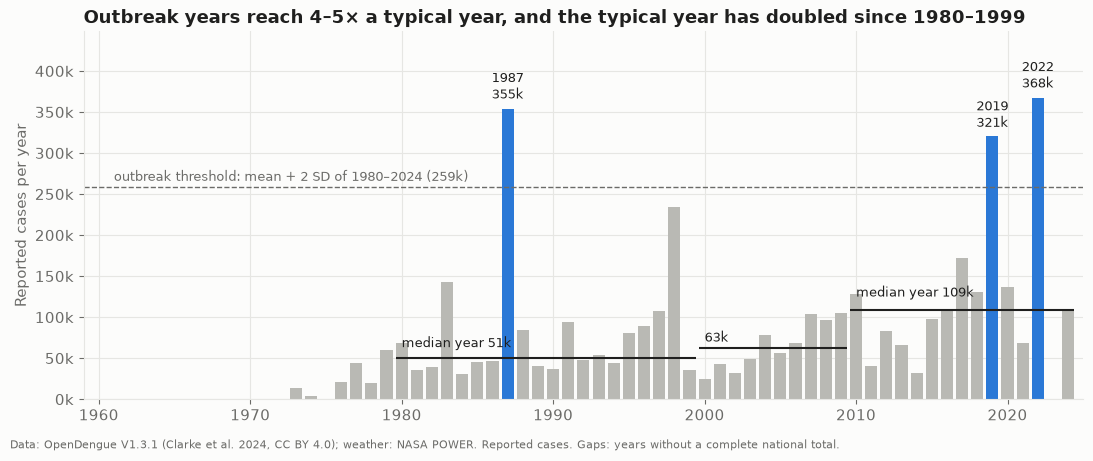

In [24]:
fig, ax = plt.subplots(figsize=(11, 4.6))
years = range(1960, 2025)
vals = national.cases.reindex(years)
colors = [COLORS["South"] if y in outbreaks.index else NEUTRAL for y in years]
ax.bar(list(years), vals.fillna(0), color=colors, width=0.8)
ax.axhline(threshold, color=MUTED, lw=1, ls="--")
ax.text(1961, threshold * 1.03, f"outbreak threshold: mean + 2 SD of 1980–2024 ({threshold / 1e3:,.0f}k)", color=MUTED, fontsize=9)
for y, c in outbreaks.items():
    ax.text(y, c * 1.02, f"{y}\n{c / 1e3:,.0f}k", ha="center", va="bottom", fontsize=9, color=INK)
for (a, b), m in zip([(1980, 1999), (2000, 2009), (2010, 2024)], baseline.values()):
    ax.hlines(m, a - 0.4, b + 0.4, color=INK, lw=1.5)
ax.text(2010, list(baseline.values())[2] * 1.15, f"median year {list(baseline.values())[2] / 1e3:,.0f}k", fontsize=9, color=INK)
ax.text(1980, list(baseline.values())[0] * 1.25, f"median year {list(baseline.values())[0] / 1e3:,.0f}k", fontsize=9, color=INK)
ax.text(2000, list(baseline.values())[1] * 1.12, f"{list(baseline.values())[1] / 1e3:,.0f}k", fontsize=9, color=INK)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v / 1e3:,.0f}k"))
ax.set_ylim(0, outbreaks.max() * 1.22)
ax.set_xlim(1959, 2025)
ax.set(ylabel="Reported cases per year", xlabel="")
ax.set_title("Outbreak years reach 4–5× a typical year, and the typical year has doubled since 1980–1999")
finish(fig, "01_national_trend.png", SOURCE + " Gaps: years without a complete national total.")

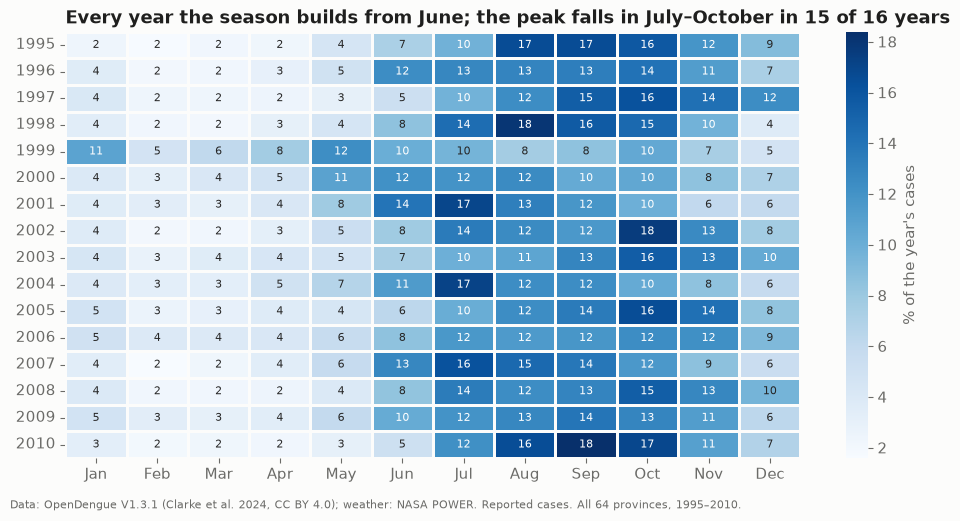

In [25]:
fig, ax = plt.subplots(figsize=(10, 5.2))
sns.heatmap(nat_share.round(1), cmap="Blues", ax=ax, cbar_kws={"label": "% of the year's cases"},
            linewidths=2, linecolor=SURFACE, annot=True, fmt=".0f", annot_kws={"fontsize": 8})
ax.set_xticklabels(MONTH_ABBR, rotation=0)
ax.grid(False)
ax.set(xlabel="", ylabel="")
ax.set_title(f"Every year the season builds from June; the peak falls in July–October in {peak_by_year.between(7, 10).sum()} of {len(peak_by_year)} years")
finish(fig, "02_heatmap_year_month.png", SOURCE + " All 64 provinces, 1995–2010.")

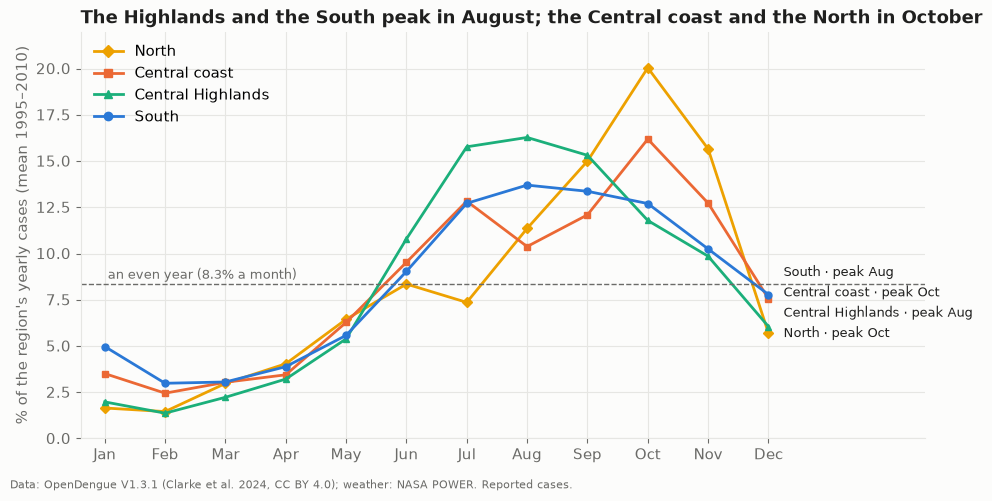

In [26]:
fig, ax = plt.subplots(figsize=(10, 5))
ends = spread({r: reg_profile.loc[r, 12] for r in ORDER}, 1.1)
for r in ORDER:
    s = reg_profile.loc[r]
    ax.plot(range(1, 13), s.values, color=COLORS[r], marker=MARKERS[r], ms=5)
    ax.text(12.25, ends[r], f"{r} · peak {MONTH_ABBR[s.idxmax() - 1]}", fontsize=9.5, color=INK, va="center")
ax.axhline(avg, color=MUTED, lw=1, ls="--")
ax.text(1.05, avg + 0.3, "an even year (8.3% a month)", fontsize=9, color=MUTED)
ax.set_xticks(range(1, 13), MONTH_ABBR)
ax.set(ylabel="% of the region's yearly cases (mean 1995–2010)", ylim=(0, 22), xlim=(0.6, 14.6))
ax.legend([plt.Line2D([], [], color=COLORS[r], lw=2, marker=MARKERS[r]) for r in ORDER], ORDER, frameon=False, loc="upper left")
ax.set_title("The Highlands and the South peak in August; the Central coast and the North in October")
finish(fig, "03_region_profiles.png")

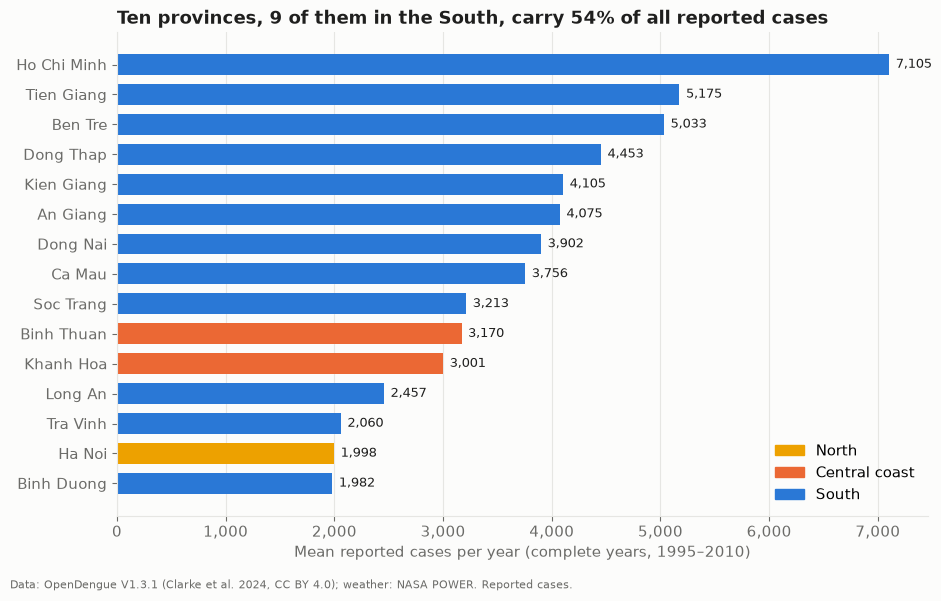

In [27]:
top = rank.head(15).iloc[::-1]
names = top.index.str.title().str.replace(" City", "")
fig, ax = plt.subplots(figsize=(9.5, 6))
ax.barh(names, top.mean_cases_per_year, color=[COLORS[r] for r in top.region], height=0.7)
for i, v in enumerate(top.mean_cases_per_year):
    ax.text(v + 60, i, f"{v:,.0f}", va="center", fontsize=9, color=INK)
shown = [r for r in ORDER if r in set(top.region)]
ax.legend([plt.Rectangle((0, 0), 1, 1, color=COLORS[r]) for r in shown], shown, frameon=False, loc="lower right")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set(xlabel="Mean reported cases per year (complete years, 1995–2010)", ylabel="")
ax.grid(axis="y", visible=False)
ax.set_title(f"Ten provinces, {(rank.region[:10] == 'South').sum()} of them in the South, carry {top10_share:.0f}% of all reported cases")
finish(fig, "04_top_provinces.png")

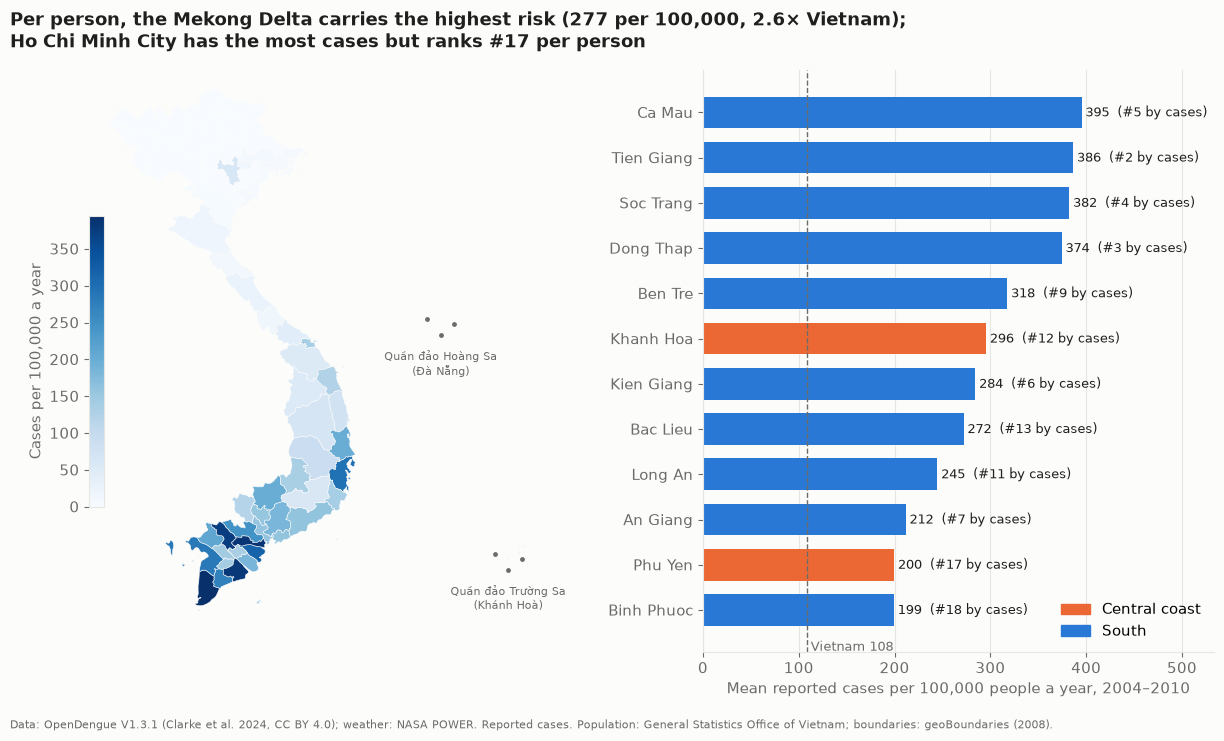

In [28]:
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.colors import Normalize

geo = json.load(open(RAW / "boundaries" / "geoBoundaries-VNM-ADM1_simplified.geojson", encoding="utf-8"))
def rings(geom):
    polys = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
    return [p[0] for p in polys]
def centroid(ring):
    x, y = np.array(ring).T
    a = x[:-1] * y[1:] - x[1:] * y[:-1]
    A = a.sum() / 2
    return ((x[:-1] + x[1:]) * a).sum() / (6 * A), ((y[:-1] + y[1:]) * a).sum() / (6 * A), abs(A)

patches, values, cents = [], [], {}
for f in geo["features"]:
    k = key(f["properties"]["shapeName"].strip())
    for r in rings(f["geometry"]):
        patches.append(MplPolygon(np.array(r), closed=True))
        values.append(incidence.incidence.get(k, np.nan))
        cx, cy, area = centroid(r)
        if area > cents.get(k, (0, 0, 0))[2]:
            cents[k] = (cx, cy, area)          # centroid of the largest part (mainland, not islands)
incidence["lon"] = [cents[k][0] for k in incidence.index]
incidence["lat"] = [cents[k][1] for k in incidence.index]

fig, (axm, axb) = plt.subplots(1, 2, figsize=(12.5, 7.4), gridspec_kw={"width_ratios": [1.35, 1.2]})
norm = Normalize(0, incidence.incidence.max())
pc = PatchCollection(patches, cmap="Blues", norm=norm, edgecolor=SURFACE, linewidth=0.4)
pc.set_array(np.array(values))
axm.add_collection(pc)
axm.set_xlim(102, 116.5); axm.set_ylim(7.5, 23.6)
# the boundary file has no islands offshore: mark the Hoang Sa and Truong Sa archipelagos (Vietnam) explicitly
for (lon, lat, label) in [(112.0, 16.5, "Quần đảo Hoàng Sa\n(Đà Nẵng)"), (114.0, 9.8, "Quần đảo Trường Sa\n(Khánh Hoà)")]:
    axm.scatter([lon - 0.4, lon, lon + 0.4], [lat + 0.25, lat - 0.2, lat + 0.1], s=6, color=MUTED, zorder=3)
    axm.text(lon, lat - 0.6, label, ha="center", va="top", fontsize=8, color=MUTED)
axm.set_aspect(1 / np.cos(np.radians(16)))
axm.axis("off")
cb = fig.colorbar(pc, ax=axm, shrink=0.5, pad=0.0, location="left")
cb.set_label("Cases per 100,000 a year", color=MUTED)
top = incidence.head(12).iloc[::-1]
axb.barh(top.province.str.title().str.replace(" City", ""), top.incidence, color=[COLORS[r] for r in top.region], height=0.7)
for i, (v, rc) in enumerate(zip(top.incidence, top.rank_cases)):
    axb.text(v + 4, i, f"{v:,.0f}  (#{rc} by cases)", va="center", fontsize=9, color=INK)
axb.axvline(national_rate, color=MUTED, lw=1, ls="--")
axb.text(national_rate + 4, -0.9, f"Vietnam {national_rate:,.0f}", fontsize=9, color=MUTED)
shown = [r for r in ORDER if r in set(top.region)]
axb.legend([plt.Rectangle((0, 0), 1, 1, color=COLORS[r]) for r in shown], shown, frameon=False, loc="lower right")
axb.set(xlabel="Mean reported cases per 100,000 people a year, 2004–2010", xlim=(0, incidence.incidence.max() * 1.35))
axb.grid(axis="y", visible=False)
fig.suptitle(f"Per person, the Mekong Delta carries the highest risk ({mekong_rate:,.0f} per 100,000, {mekong_rate / national_rate:.1f}× Vietnam);\n"
             f"Ho Chi Minh City has the most cases but ranks #{incidence.loc['HOCHIMINH', 'rank_incidence']} per person",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
finish(fig, "08_incidence_map.png", SOURCE + " Population: General Statistics Office of Vietnam; boundaries: geoBoundaries (2008).")

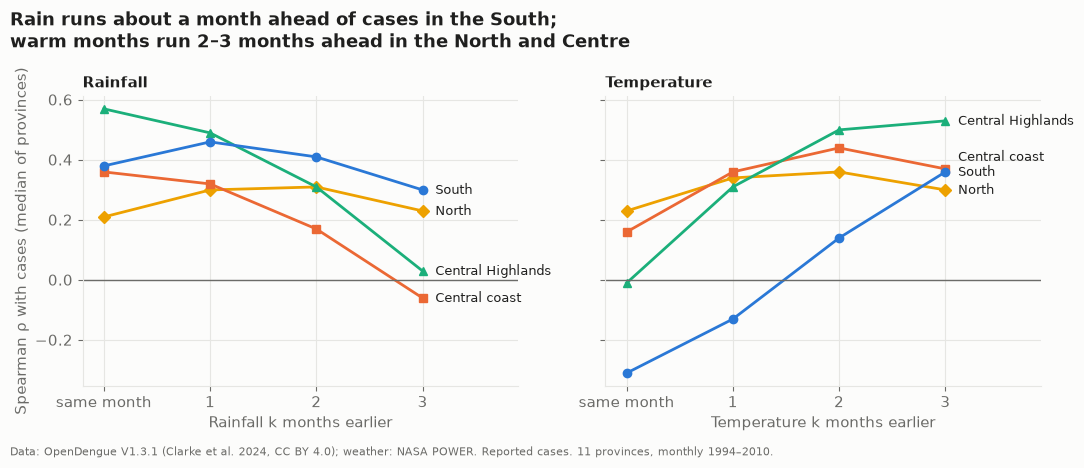

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, var, label in [(axes[0], "rain_seasonal", "Rainfall k months earlier"), (axes[1], "temp_seasonal", "Temperature k months earlier")]:
    ends = spread({r: by_region.loc[r][var].iloc[-1] for r in ORDER}, 0.05)
    for r in ORDER:
        s = by_region.loc[r][var]
        ax.plot(s.index, s.values, color=COLORS[r], marker=MARKERS[r], ms=6)
        ax.text(3.12, ends[r], r, fontsize=9, color=INK, va="center")
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_xticks(range(4), ["same month", "1", "2", "3"])
    ax.set(xlabel=label, xlim=(-0.2, 3.9))
    ax.set_title(label.split(" k")[0], fontsize=11)
axes[0].set_ylabel("Spearman ρ with cases (median of provinces)")
fig.suptitle("Rain runs about a month ahead of cases in the South;\nwarm months run 2–3 months ahead in the North and Centre",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
finish(fig, "05_weather_lead.png", SOURCE + " 11 provinces, monthly 1994–2010.")

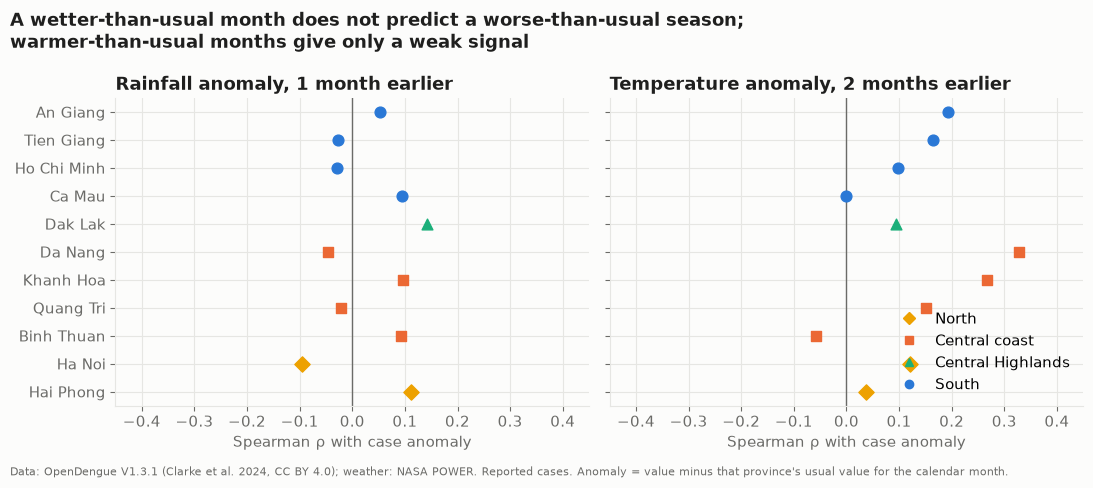

In [30]:
sel = pd.concat([lags[lags.lag == 1].assign(measure="Rainfall anomaly, 1 month earlier", rho=lambda d: d.rain_anomaly),
                 lags[lags.lag == 2].assign(measure="Temperature anomaly, 2 months earlier", rho=lambda d: d.temp_anomaly)])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
order = lags[lags.lag == 2].sort_values("temp_anomaly").province
for ax, (m, g) in zip(axes, sel.groupby("measure")):
    g = g.set_index("province").loc[order]
    ax.axvline(0, color=MUTED, lw=1)
    yl = g.index.str.title().str.replace(" City", "")
    for r in ORDER:
        mask = (g.region == r).values
        ax.scatter(g.rho[mask], yl[mask], color=COLORS[r], marker=MARKERS[r], s=60, zorder=3)
    ax.set(xlim=(-0.45, 0.45), xlabel="Spearman ρ with case anomaly", title=m)
    ax.title.set_fontsize(11)
axes[1].legend([plt.Line2D([], [], marker=MARKERS[r], ls="", color=COLORS[r]) for r in ORDER], ORDER, frameon=False, loc="lower right")
fig.suptitle("A wetter-than-usual month does not predict a worse-than-usual season;\nwarmer-than-usual months give only a weak signal",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
finish(fig, "06_weather_anomaly.png", SOURCE + " Anomaly = value minus that province's usual value for the calendar month.")

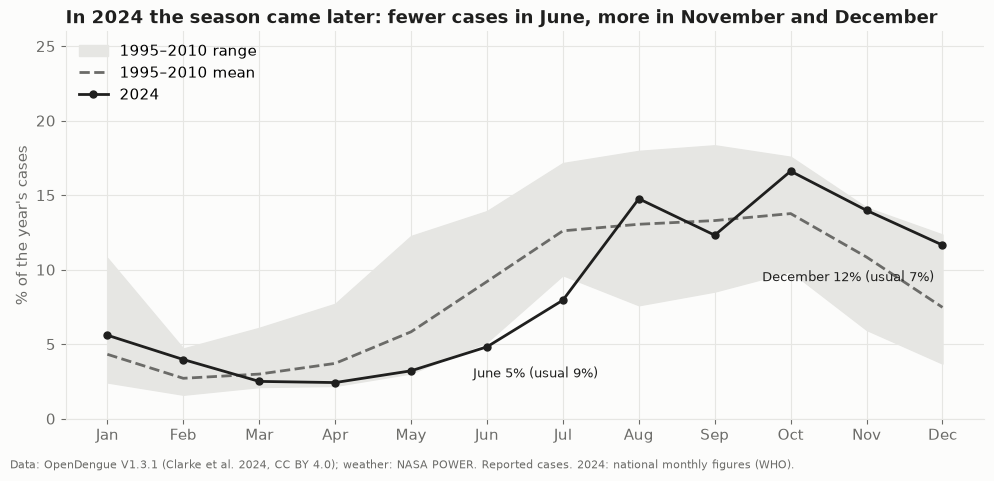

In [31]:
fig, ax = plt.subplots(figsize=(10, 4.8))
lo, hi = nat_share.min(), nat_share.max()
ax.fill_between(range(1, 13), lo.values, hi.values, color=GRID, label="1995–2010 range")
ax.plot(range(1, 13), profile.values, color=MUTED, ls="--", label="1995–2010 mean")
ax.plot(range(1, 13), s24.reindex(range(1, 13)).values, color=INK, marker="o", ms=5, label="2024")
ax.annotate(f"June {s24[6]:.0f}% (usual {profile[6]:.0f}%)", (6, s24[6]), xytext=(-10, -22), textcoords="offset points", fontsize=9, color=INK)
ax.annotate(f"December {s24[12]:.0f}% (usual {profile[12]:.0f}%)", (12, s24[12]), xytext=(-6, -26), textcoords="offset points", fontsize=9, color=INK, ha="right")
ax.set_xticks(range(1, 13), MONTH_ABBR)
ax.set(ylabel="% of the year's cases", ylim=(0, 26))
ax.legend(frameon=False, loc="upper left")
ax.set_title("In 2024 the season came later: fewer cases in June, more in November and December")
finish(fig, "07_recent_season_2024.png", SOURCE + " 2024: national monthly figures (WHO).")

In [32]:
# Files for the Tableau Public dashboard
TITLE = lambda s: s.str.title().str.replace(" City", "").str.replace("Thua Thien - Hue", "Thua Thien Hue")
(prov.assign(province=TITLE(prov.province)).drop(columns="slug")
     .to_csv(CLEAN / "tableau_province_month.csv", index=False))
reg_profile.stack().rename("pct_of_year").reset_index().to_csv(CLEAN / "tableau_region_profile.csv", index=False)
lags.round(3).to_csv(CLEAN / "tableau_weather_lag.csv", index=False)
national.reset_index().to_csv(CLEAN / "tableau_national_annual.csv", index=False)
(incidence.assign(province=TITLE(incidence.province)).reset_index(drop=True)
     .round({"incidence": 1, "cases_per_year": 0, "population_thousand": 1, "lat": 4, "lon": 4})
     .to_csv(CLEAN / "tableau_incidence.csv", index=False))
sorted(p.name for p in CLEAN.glob("tableau_*.csv"))

['tableau_incidence.csv',
 'tableau_national_annual.csv',
 'tableau_province_month.csv',
 'tableau_region_profile.csv',
 'tableau_weather_lag.csv']

## 6. Act
**Top high-level insights**
1. Dengue in Vietnam is a **predictable June–November season** (73% of cases), and the calendar alone tells the client when to prepare.
2. **Where matters more than when:** the South carries 68% of cases, and per person the Mekong Delta runs at 2.6× the national rate. Ho Chi Minh City leads in cases only because it is large.
3. **Regions are staggered:** the Highlands and the South climb fastest and peak in August; the Central coast and the North peak in October, and the North only climbs from August.
4. **Weather confirms timing but does not forecast severity:** rain runs about a month ahead of cases in the Mekong Delta, yet a wetter-than-usual month does not mean a worse season. Bad years (4–5× normal) arrive every few years and need surge capacity, not a rain forecast.
5. **The baseline is rising and recent seasons run later:** the typical year doubled since the 1990s, and in 2024 cases stayed high into December.

**Recommendations for the client**
1. **Regional preparation calendar:** stock and staff in place by **May** in the South, the Central Highlands and the Central coast (cases rise from June; the coast has a July hump before its October peak) and by **July** in the North (cases climb from August, peak in October); keep crews on until **December**, as in 2024.
2. **Allocate by burden, two ways:** size crews by case counts (about two thirds of capacity to the South, led by Ho Chi Minh City and the large Mekong Delta provinces; a quarter to the Central coast), and set the intensity of household-level larval control by incidence, highest in Ca Mau, Tien Giang, Soc Trang, Dong Thap, Ben Tre and Khanh Hoa; keep a flexible reserve for the North, whose rare outbreaks are large.
3. **Use weather as a timing trigger, not a severity forecast:** start larval-control campaigns in the South when the rainy season sets in (May–June); plan a surge contract for outbreak years instead of scaling with rainfall.

**Additional deliverables for further exploration**
- Incidence for the latest years once province data after 2010 is available (Ministry of Health / Pasteur Institutes), mapped to the 34 provinces created in 2025.
- District-level cases inside Ho Chi Minh City and the Mekong Delta, to find hotspots within large provinces.
- An early-warning model that combines lagged cases, temperature anomalies and El Niño indices, tested on held-out years.
- Entomological indices (Breteau, House index), if the client can share them.
- A monthly Tableau dashboard refreshed as new national figures are published.